In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Load customer segmentation results
segments = pd.read_csv("../data/customer_segments.csv")
profile = pd.read_csv("../data/cluster_profile.csv")

print("Customer segments shape:", segments.shape)
print("Cluster profile shape:", profile.shape)

display(segments.head())
display(profile)

Customer segments shape: (4338, 5)
Cluster profile shape: (4, 7)


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,2
4,12350,310,1,334.40,1


,Cluster,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
0,0,713,12.17,13.75,8088.02,3722.82,16.44
1,1,1622,181.51,1.32,341.00,296.09,37.39
2,2,837,17.70,2.19,557.32,480.31,19.29
3,3,1166,71.64,4.08,1801.78,1345.20,26.88


In [2]:
profile = profile.sort_values("Cluster").reset_index(drop=True)

display(profile)

,Cluster,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
0,0,713,12.17,13.75,8088.02,3722.82,16.44
1,1,1622,181.51,1.32,341.00,296.09,37.39
2,2,837,17.70,2.19,557.32,480.31,19.29
3,3,1166,71.64,4.08,1801.78,1345.20,26.88


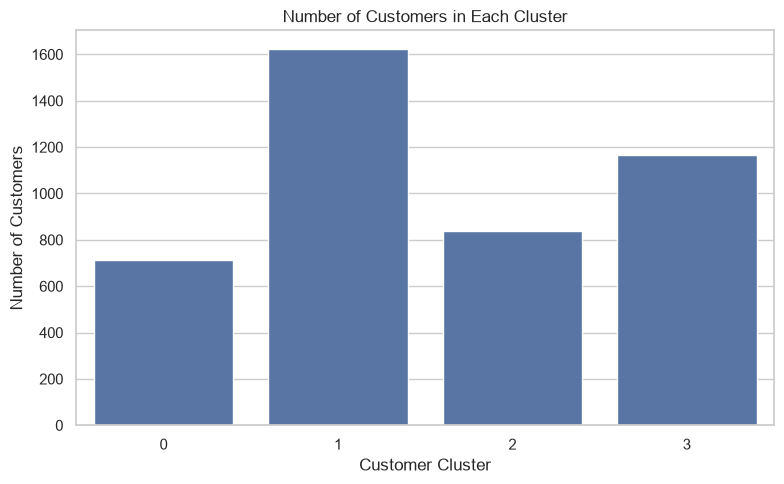

In [3]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=profile,
    x="Cluster",
    y="Customer_Count"
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

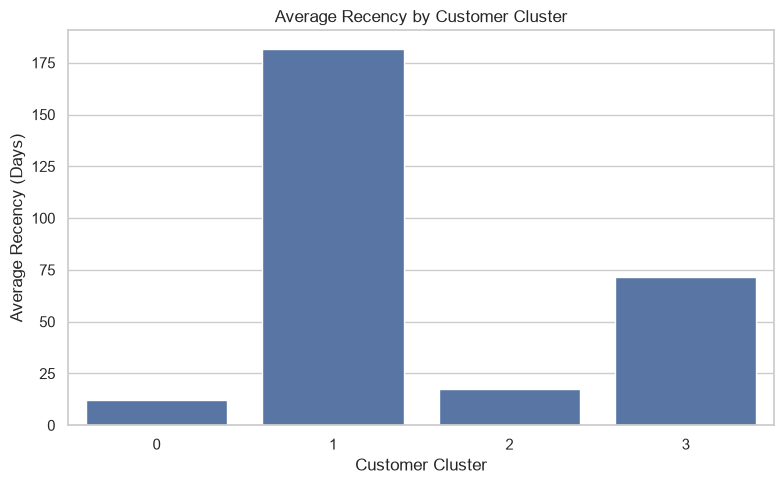

In [4]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=profile,
    x="Cluster",
    y="Avg_Recency"
)

plt.title("Average Recency by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Recency (Days)")
plt.tight_layout()
plt.show()

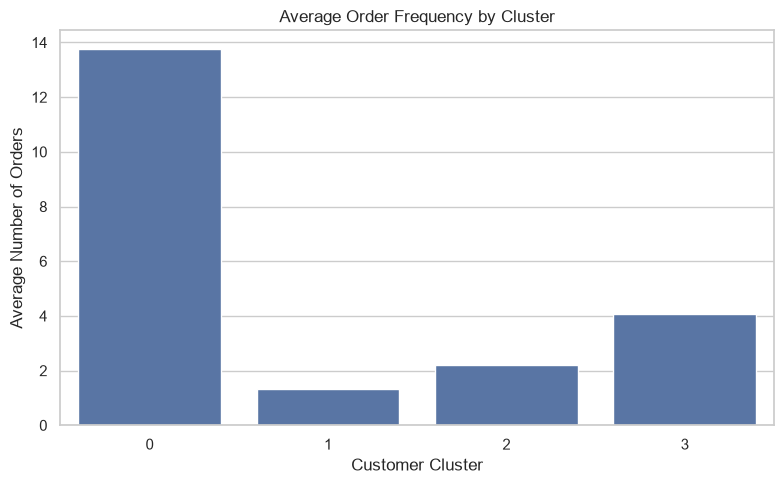

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=profile,
    x="Cluster",
    y="Avg_Frequency"
)

plt.title("Average Order Frequency by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Number of Orders")
plt.tight_layout()
plt.show()

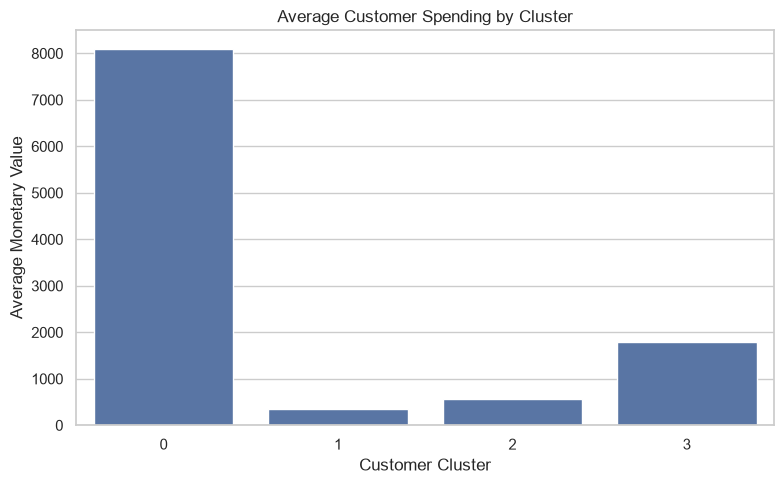

In [6]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=profile,
    x="Cluster",
    y="Avg_Monetary"
)

plt.title("Average Customer Spending by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Monetary Value")
plt.tight_layout()
plt.show()

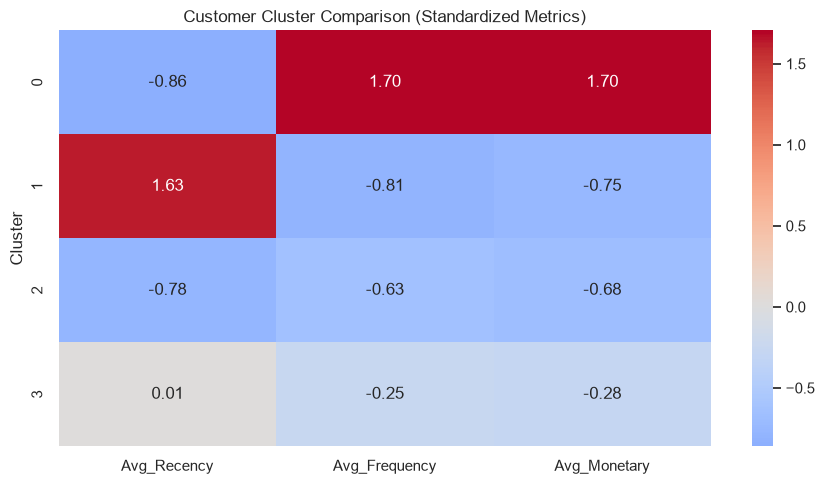

In [7]:
heatmap_data = profile.set_index("Cluster")[
    ["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]
]

# Put metrics on comparable scales for visual comparison
heatmap_scaled = (
    heatmap_data - heatmap_data.mean()
) / heatmap_data.std(ddof=0)

plt.figure(figsize=(9, 5))

sns.heatmap(
    heatmap_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Customer Cluster Comparison (Standardized Metrics)")
plt.tight_layout()
plt.show()

In [8]:
profile = profile.copy()

# Relative ranks: lower recency is better
profile["Recency_Rank"] = profile["Avg_Recency"].rank(
    ascending=True, pct=True
)

profile["Frequency_Rank"] = profile["Avg_Frequency"].rank(
    ascending=True, pct=True
)

profile["Monetary_Rank"] = profile["Avg_Monetary"].rank(
    ascending=True, pct=True
)

profile["Value_Score"] = (
    profile["Frequency_Rank"] +
    profile["Monetary_Rank"] +
    (1 - profile["Recency_Rank"])
) / 3

display(
    profile[
        [
            "Cluster",
            "Avg_Recency",
            "Avg_Frequency",
            "Avg_Monetary",
            "Value_Score"
        ]
    ].sort_values("Value_Score", ascending=False)
)

,Cluster,Avg_Recency,Avg_Frequency,Avg_Monetary,Value_Score
0,0,12.17,13.75,8088.02,0.916667
3,3,71.64,4.08,1801.78,0.583333
2,2,17.70,2.19,557.32,0.500000
1,1,181.51,1.32,341.00,0.166667


In [9]:
def describe_cluster(row):
    recency_mid = profile["Avg_Recency"].median()
    frequency_mid = profile["Avg_Frequency"].median()
    monetary_mid = profile["Avg_Monetary"].median()

    if (
        row["Avg_Recency"] <= recency_mid
        and row["Avg_Frequency"] >= frequency_mid
        and row["Avg_Monetary"] >= monetary_mid
    ):
        return "High Value / Active"

    elif (
        row["Avg_Frequency"] >= frequency_mid
        and row["Avg_Recency"] <= recency_mid
    ):
        return "Frequent / Recently Active"

    elif row["Avg_Recency"] > recency_mid:
        return "Needs Engagement Review"

    else:
        return "Lower Relative Activity / Spend"


profile["Suggested_Segment"] = profile.apply(
    describe_cluster,
    axis=1
)

display(profile)

,Cluster,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage,Recency_Rank,Frequency_Rank,Monetary_Rank,Value_Score,Suggested_Segment
0,0,713,12.17,13.75,8088.02,3722.82,16.44,0.25,1.00,1.00,0.916667,High Value / Active
1,1,1622,181.51,1.32,341.00,296.09,37.39,1.00,0.25,0.25,0.166667,Needs Engagement Review
2,2,837,17.70,2.19,557.32,480.31,19.29,0.50,0.50,0.50,0.500000,Lower Relative Activity / Spend
3,3,1166,71.64,4.08,1801.78,1345.20,26.88,0.75,0.75,0.75,0.583333,Needs Engagement Review


In [10]:
label_map = profile.set_index("Cluster")["Suggested_Segment"]

segments["Suggested_Segment"] = segments["Cluster"].map(label_map)

segments.to_csv(
    "../data/customer_segments_labeled.csv",
    index=False
)

profile.to_csv(
    "../data/cluster_profile.csv",
    index=False
)

print("Labeled customer segments saved!")
print("Updated cluster profile saved!")

Labeled customer segments saved!
Updated cluster profile saved!


In [11]:
print("Total customers:", len(segments))
print("Unique customer IDs:", segments["CustomerID"].nunique())

print("\nCustomers per cluster:")
print(segments["Cluster"].value_counts().sort_index())

print("\nMissing values:")
print(
    segments[
        ["Recency", "Frequency", "Monetary", "Cluster"]
    ].isna().sum()
)

print("\nSuggested segment labels:")
print(segments["Suggested_Segment"].value_counts())

Total customers: 4338
Unique customer IDs: 4338

Customers per cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

Missing values:
Recency      0
Frequency    0
Monetary     0
Cluster      0
dtype: int64

Suggested segment labels:
Suggested_Segment
Needs Engagement Review            2788
Lower Relative Activity / Spend     837
High Value / Active                 713
Name: count, dtype: int64


In [1]:
import pandas as pd

cleaned = pd.read_csv(
    "../data/online_retail_cleaned.csv"
)

print("Rows:", len(cleaned))
print("Columns:", cleaned.columns.tolist())

print("\nMissing values:")
print(cleaned.isna().sum())

print("\nDuplicate rows:", cleaned.duplicated().sum())

print("\nRevenue sample:")
display(
    cleaned[
        ["Quantity", "UnitPrice", "Revenue"]
    ].head()
)

Rows: 392688
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

Duplicate rows: 0

Revenue sample:


,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [11]:
import sqlite3
import pandas as pd

connection = sqlite3.connect("../data/ecommerce.db")

result = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT CustomerID) AS unique_customers,
        ROUND(SUM(Revenue), 2) AS total_revenue
    FROM sales
    """,
    connection
)

display(result)

connection.close()

,total_rows,unique_customers,total_revenue
0,392688,4338,8887208.89


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries working successfully!")
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

ImportError: 

IMPORTANT: PLEASE READ THIS FOR ADVICE ON HOW TO SOLVE THIS ISSUE!

Importing the numpy C-extensions failed. This error can happen for
many reasons, often due to issues with your setup or how NumPy was
installed.
The following compiled module files exist, but seem incompatible
with with either python 'cpython-313' or the platform 'win32':

  * _multiarray_umath.cp315-win_amd64.lib
  * _multiarray_umath.cp315-win_amd64.pyd

We have compiled some common reasons and troubleshooting tips at:

    https://numpy.org/devdocs/user/troubleshooting-importerror.html

Please note and check the following:

  * The Python version is: Python 3.13 from "o:\New folder (2)\ecommerce-customer-intelligence\.venv\Scripts\python.exe"
  * The NumPy version is: "2.5.5"

and make sure that they are the versions you expect.

Please carefully study the information and documentation linked above.
This is unlikely to be a NumPy issue but will be caused by a bad install
or environment on your machine

In [6]:
import sys
print(sys.executable)

o:\New folder (2)\ecommerce-customer-intelligence\.venv\Scripts\python.exe


In [9]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/ecommerce.db")

pd.read_sql("""
SELECT COUNT(*) AS total_rows
FROM transactions
""", conn)


DatabaseError: Execution failed on sql '
SELECT COUNT(*) AS total_rows
FROM transactions
': no such table: transactions

In [3]:
import os
print(os.getcwd())

o:\New folder (2)\ecommerce-customer-intelligence\notebooks


In [4]:
conn = sqlite3.connect("../data/ecommerce.db")

In [5]:
import os

print(os.path.exists("../data/ecommerce.db"))

True


In [6]:
import sqlite3

conn = sqlite3.connect("../data/ecommerce.db")

In [7]:
conn = sqlite3.connect(
    r"O:\New folder (2)\ecommerce-customer-intelligence\data\ecommerce.db"
)

In [8]:
import os

print(os.listdir("../data"))

['cluster_profile.csv', 'customer_rfm.csv', 'customer_segments.csv', 'customer_segments_labeled.csv', 'ecommerce.db', 'incremental_demo.db', 'Online Retail.xlsx', 'online_retail_cleaned.csv']


In [10]:
cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table';
""")

print(cursor.fetchall())

[('sales',)]
